In [1]:
import os


os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "1.00"

import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import src.figure_utilities as figure_utilities
from src.parameters import COLORS
import logging

logging.basicConfig(
    level=logging.INFO, format="%(asctime)s %(message)s", datefmt="%d-%b-%y %H:%M:%S"
)


figure_utilities.set_figure_defaults(context="paper")
warnings.filterwarnings("ignore")

In [2]:
plt.rcParams.update(
    {
        "font.size": 18,  # General font size
        "axes.titlesize": 20,  # Font size for axes titles
        "axes.labelsize": 18,  # Font size for axes labels
        "xtick.labelsize": 16,  # Font size for x-tick labels
        "ytick.labelsize": 16,  # Font size for y-tick labels
        "legend.fontsize": 16,  # Font size for legend
        "figure.titlesize": 22,  # Font size for figure title
    }
)

In [3]:
import pandas as pd
from pathlib import Path


data_path = Path("/cumulus/edeno/non_local_paper/Processed-Data").glob(
    "*_HPC_80_data_over_time.pkl"
)

data_over_time = pd.concat([pd.read_pickle(p) for p in data_path])
data_over_time["Non-Local_prob"] = (
    data_over_time["Non-Local_Continuous_prob"]
    + data_over_time["Non-Local_Fragmented_prob"]
)
data_over_time["distance"] = np.abs(data_over_time["ahead_behind_distance"])

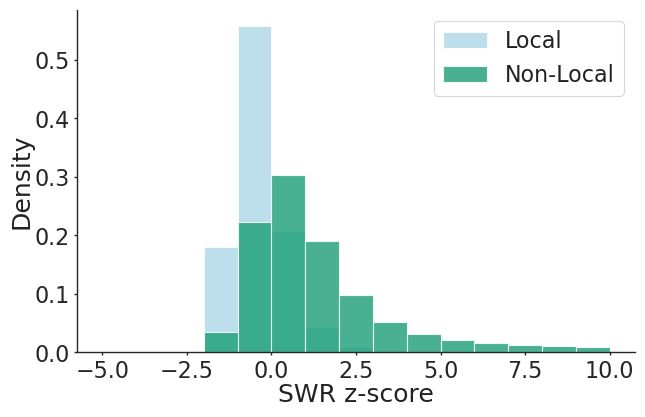

In [4]:
plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time.head_speed < 4.0, data_over_time["Local_prob"] > 0.8
        ),
        "SWR_zscore",
    ],
    bins=np.arange(-5, 11),
    alpha=0.8,
    density=True,
    label="Local",
    color=COLORS["Local"],
)
plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time.head_speed < 4.0, data_over_time["Non-Local_prob"] > 0.8
        ),
        "SWR_zscore",
    ],
    bins=np.arange(-5, 11),
    alpha=0.8,
    density=True,
    label="Non-Local",
    color=COLORS["Non-Local"],
)
plt.legend()
plt.ylabel("Density")
plt.xlabel("SWR z-score")
sns.despine()

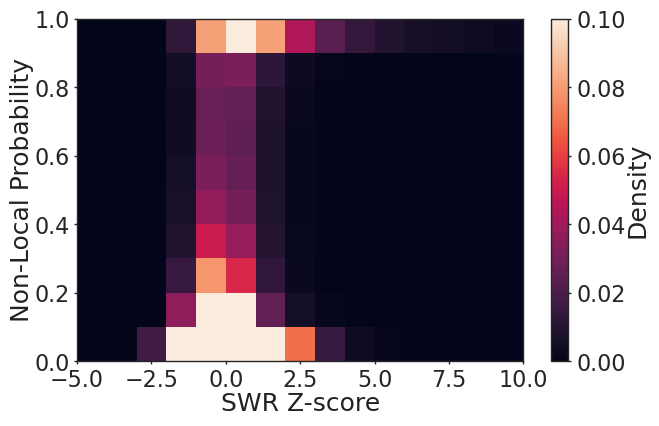

In [5]:
plt.hist2d(
    data_over_time.loc[data_over_time.head_speed < 4.0]["SWR_zscore"],
    data_over_time.loc[data_over_time.head_speed < 4.0]["Non-Local_prob"],
    bins=(np.arange(-5, 11), np.arange(0, 1.1, 0.1)),
    vmin=0.0,
    vmax=0.1,
    density=True,
)
plt.xlabel("SWR Z-score")
plt.ylabel("Non-Local Probability")
plt.colorbar(label="Density")

Text(0.5, 0, 'Linear position')

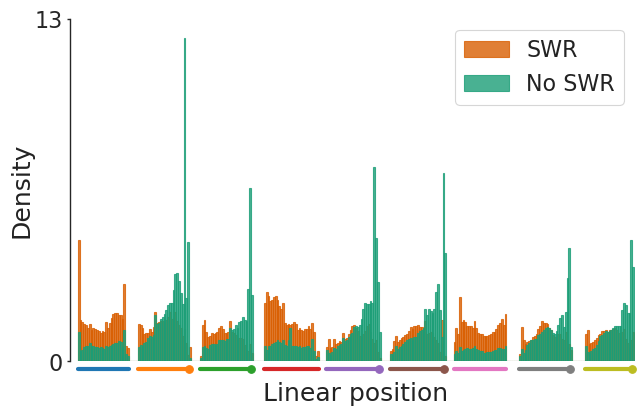

In [6]:
bins = int(np.median(data_over_time["max_linear_position"].unique() / 2))
density, bins, _ = plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time["non_local_event"] > 0, data_over_time["SWR_event"] > 0
        ),
        "map_estimate",
    ]
    / data_over_time.loc[data_over_time["non_local_event"] > 0, "max_linear_position"],
    bins=bins,
    density=True,
    alpha=0.8,
    color=COLORS["SWR"],
    edgecolor=COLORS["SWR"],
    label="SWR",
)
plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time["non_local_event"] > 0, data_over_time["SWR_event"] == 0
        ),
        "map_estimate",
    ]
    / data_over_time.loc[data_over_time["non_local_event"] > 0, "max_linear_position"],
    bins=bins,
    density=True,
    alpha=0.8,
    color=COLORS["Non-Local"],
    edgecolor=COLORS["Non-Local"],
    label="No SWR",
)
plt.legend()


from scipy.ndimage import label

bin_labels, n_labels = label(density)

well_labels = [2, 3, 5, 6, 8, 9]
edge_colors = np.array(matplotlib.colormaps.get_cmap("tab10").colors)
track_line_y = -0.3

for i in range(1, n_labels + 1):
    bin_ind = np.nonzero(bin_labels == i)[0]
    plt.plot(
        (bins[bin_ind[0]], bins[bin_ind[-1] + 1]),
        (track_line_y, track_line_y),
        zorder=10,
        clip_on=False,
        color=edge_colors[i - 1],
        linewidth=3,
    )

    if i in well_labels:
        plt.scatter(
            bins[bin_ind[-1]],
            track_line_y,
            zorder=11,
            clip_on=False,
            color=edge_colors[i - 1],
            s=30,
        )

plt.xlim((0, 1))
plt.yticks([0, 13])
plt.ylim((0, 13))
plt.ylabel("Density")
# Hide x-axis and x line
sns.despine(offset=5)
plt.gca().get_xaxis().set_ticks([])
plt.gca().spines["bottom"].set_visible(False)
plt.xlabel("Linear position", labelpad=10)

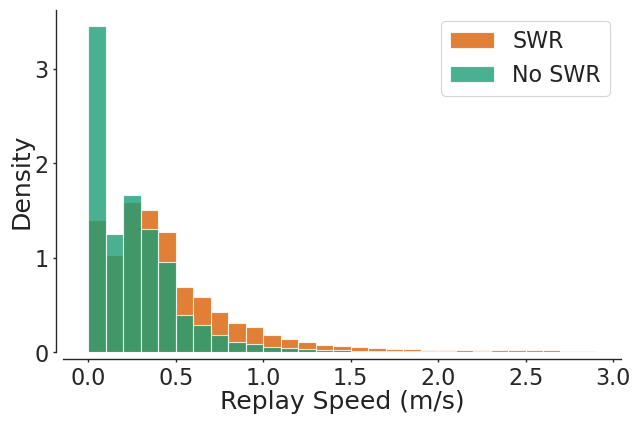

In [7]:
bins = np.arange(0, 3, 0.1)
plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time["non_local_event"] > 0, data_over_time["SWR_event"] > 0
        ),
        "map_speed",
    ]
    / 1000,
    bins=bins,
    density=True,
    alpha=0.8,
    color=COLORS["SWR"],
    label="SWR",
)
plt.hist(
    data_over_time.loc[
        np.logical_and(
            data_over_time["non_local_event"] > 0, data_over_time["SWR_event"] == 0
        ),
        "map_speed",
    ]
    / 1000,
    bins=bins,
    density=True,
    alpha=0.8,
    color=COLORS["Non-Local"],
    label="No SWR",
)
plt.legend()
plt.xlabel("Replay Speed (m/s)")
plt.ylabel("Density")
sns.despine(offset=5)

In [8]:
data_over_time.columns

Index(['non_local_event', 'SWR_event', 'MUA_event', 'Local_prob',
       'No-Spike_prob', 'Non-Local_Continuous_prob',
       'Non-Local_Fragmented_prob', 'map_estimate', 'map_speed',
       'ahead_behind_distance', 'hpd', 'max_coverage', 'max_distance',
       'max_linear_position', 'theta_phase', 'theta_power_zscore',
       'SWR_zscore', 'MUA_zscore', 'n_non_local', 'n_SWR', 'n_MUA',
       'n_non_local_SWR', 'n_non_local_no_SWR', 'n_non_local_MUA',
       'n_non_local_no_MUA', 'n_SWR_MUA', 'n_SWR_no_MUA', 'animal', 'day',
       'epoch', 'nwb_file_name', 'head_position_x', 'head_position_y',
       'head_orientation', 'head_velocity_x', 'head_velocity_y', 'head_speed',
       'linear_position', 'track_segment_id', 'projected_x_position',
       'projected_y_position', 'Non-Local_prob', 'distance'],
      dtype='object')

In [9]:
is_immobile = data_over_time["head_speed"] < 4.0
is_non_local = np.logical_and(data_over_time["Non-Local_prob"] > 0.8, is_immobile)
is_swr = np.logical_and(data_over_time["SWR_zscore"] > 2.0, is_immobile)
is_swr_and_non_local = np.logical_and(is_swr, is_non_local)

100 * (is_swr.sum() / is_immobile.sum()), 100 * (
    is_non_local.sum() / is_immobile.sum()
), 100 * (is_swr_and_non_local.sum() / is_immobile.sum())

(2.475722900754595, 5.030309873641356, 1.3159598605600347)

In [10]:
100 * ((is_swr & ~is_non_local).sum() / is_immobile.sum())

1.1597630401945604

In [11]:
100 * ((is_swr & is_non_local).sum() / is_immobile.sum())

1.3159598605600347

In [12]:
100 * ((~is_swr & is_non_local).sum() / is_immobile.sum())

3.714350013081321

In [13]:
(is_non_local.sum() / is_immobile.sum()) / (is_swr.sum() / is_immobile.sum())

2.031854967334239

In [14]:
np.percentile(data_over_time.groupby(["animal", "day", "epoch"]).apply(
    lambda x: ((x["non_local_event"] > 0) & (x["SWR_event"] > 0)).sum() / 500.0
), [25, 50, 75])

array([ 6.883 ,  8.9   , 11.8395])

# PFC

In [15]:
from non_local_detector.likelihoods.common import get_spikecount_per_time_bin


def plot_raster_relative_to_event(
    spike_times, event_times, window, ax=None, color="black"
):
    if ax is None:
        ax = plt.gca()

    event_times = np.asarray(event_times)
    relative_spike_times = []
    for event_time in event_times:
        event_relative_spike_times = spike_times - event_time

        relative_spike_times.append(
            event_relative_spike_times[
                np.logical_and(
                    event_relative_spike_times > window[0],
                    event_relative_spike_times < window[1],
                )
            ]
        )
    ax.eventplot(relative_spike_times, color=color)
    ax.set_xlim(window)
    ax.axvline(0, color="black", linestyle="--")


def plot_hist_relative_to_event(
    spike_times,
    event_times,
    window,
    ax=None,
    color="gray",
    bin_size=0.050,
):
    if ax is None:
        ax = plt.gca()

    n_bins = int((window[1] - window[0]) // bin_size)
    bins = np.arange(window[0], window[1] + bin_size, bin_size)

    event_times = np.asarray(event_times)
    relative_spike_counts = np.zeros_like(bins)
    for event_time in event_times:
        event_relative_spike_times = spike_times - event_time

        relative_spike_counts += get_spikecount_per_time_bin(
            event_relative_spike_times[
                np.logical_and(
                    event_relative_spike_times > window[0],
                    event_relative_spike_times < window[1],
                )
            ],
            bins,
        )

    n_events = len(event_times)
    ax.bar(
        bins,
        relative_spike_counts / (n_events * bin_size),
        width=bin_size,
        color=color,
        align="edge",
    )
    ax.set_xlim(window)
    ax.axvline(0, color="black", linestyle="--")


def plot_glm_results(
    lag_time,
    spline_basis,
    neuron_spike_times,
    glm_results,
    event_times,
    model_list=None,
):
    if model_list is None:
        model_list = ["SWR", "non_local_SWR", "non_local_no_SWR", "non_local"]

    fig, axes = plt.subplots(
        nrows=3,
        ncols=len(model_list),
        figsize=(2.5 * len(model_list), 5),
        sharex=True,
        sharey=False,
        constrained_layout=True,
    )
    if len(model_list) == 1:
        axes = np.expand_dims(axes, 1)

    modulation_bounds = np.log(0.5), np.log(2.0)
    lag_bounds = lag_time[0], lag_time[-1]

    models = [glm_results[event_name] for event_name in model_list]

    model_list_to_mode_names = {
        "SWR": "SWR",
        "non_local_SWR": "Non-Local,\nSWR",
        "non_local_no_SWR": "Non-Local,\nNo SWR",
        "non_local": "Non-Local",
    }
    model_names = [model_list_to_mode_names[model_name] for model_name in model_list]

    model_names_to_event = {
        "SWR": "SWR",
        "Non-Local, SWR": "non_local_SWR",
        "Non-Local, No SWR": "non_local_no_SWR",
        "Non-Local": "non_local",
    }
    # 'SWR', 'non_local_SWR', 'non_local_no_SWR', 'non_local',
    event_start_times = [
        event_times[model_name].start_time
        for model_name in model_names_to_event.values()
    ]

    for ax, model, model_name in zip(axes[0], models, model_names):
        ax.plot(lag_time, model.params[1:] @ spline_basis.T)
        ax.fill_between(
            lag_time,
            (model.params[1:] + model.bse[1:]) @ spline_basis.T,
            (model.params[1:] - model.bse[1:]) @ spline_basis.T,
            alpha=0.25,
        )
        ax.axhline(0, color="black", linestyle="--")
        ax.axvline(0, color="black", linestyle="--")
        ax.set_title(model_name)
        ax.set_ylim(modulation_bounds)
        ax.set_xticks((lag_bounds[0], 0, lag_bounds[1]))
        ax.set_yticks((modulation_bounds[0], 0, modulation_bounds[1]))
        ax.set_ylabel("Mod.")
        ax.set_yticklabels(
            (np.exp(modulation_bounds[0]), 1, np.exp(modulation_bounds[1]))
        )

    for ax, event_time in zip(axes[1], event_start_times):
        plot_raster_relative_to_event(neuron_spike_times, event_time, lag_bounds, ax)
        ax.set_ylabel("Event")

    for ax, event_time in zip(axes[2], event_start_times):
        plot_hist_relative_to_event(neuron_spike_times, event_time, lag_bounds, ax)
        ax.set_ylabel("Rate\n[sp/s]")

    fig.supxlabel("Time from\nevent start (s)")


def plot_AICs(glm_results, model_list=None):
    if model_list is None:
        model_list = [
            "constant",
            "SWR",
            "non_local_SWR",
            "non_local_no_SWR",
            "non_local",
            "SWR + non_local_no_SWR",
        ]
    fig, ax = plt.subplots(figsize=(4, 3))

    model_list_to_mode_names = {
        "constant": "Constant",
        "SWR": "SWR",
        "non_local_SWR": "Non-Local,\nSWR",
        "non_local_no_SWR": "Non-Local,\nNo SWR",
        "non_local": "Non-Local",
        "SWR + non_local_no_SWR": "SWR + Non-Local",
    }
    model_names = [model_list_to_mode_names[model_name] for model_name in model_list]

    aics = [glm_results[model_name].aic for model_name in model_list]

    ax.scatter(
        aics,
        np.arange(len(aics)),
    )
    ax.set_yticks(np.arange(len(aics)))
    ax.set_yticklabels(model_names)
    ax.set_xticks([np.min(aics), np.max(aics)])
    ax.set_xlabel("AIC (lower is better)")

In [16]:
nwb_file_name, epoch_name = "wilbur20210329_.nwb", "02_r1"

In [17]:
import numpy as np

from src.analysis_hpc_bandit import get_confident_times, get_overlap_times, load_results
from src.load_data_bandit import load_data
from src.pfc_analysis3 import _make_design_matrices, process_neuron

non_local_threshold = 0.8
immobility_threshold = 4.0
sampling_frequency = 500

results, _, _ = load_results(nwb_file_name, epoch_name, decoding_brain_area="HPC")
data = load_data(nwb_file_name, epoch_name)

non_local_prob = results.acausal_state_probabilities.sel(
    states="Non-Local Continuous"
) + results.acausal_state_probabilities.sel(states="Non-Local Fragmented")

non_local_times = get_confident_times(
    non_local_prob,
    data["position_info"].head_speed.to_numpy(),
    data["position_info"].index.to_numpy(),
    non_local_threshold,
)
non_local_times = non_local_times[non_local_times.max_speed < 4.0]

non_local_SWR_times, non_local_no_SWR_times = get_overlap_times(
    non_local_times, data["ripple_times"], results
)

event_times = {
    "non_local_no_SWR": non_local_no_SWR_times,
    "non_local_SWR": non_local_SWR_times,
    "non_local": non_local_times,
    "SWR": data["ripple_times"],
}

time = data["position_info"].index.to_numpy()
is_immobile = data["position_info"].head_speed <= immobility_threshold

immobility_design_matrices, spline_basis, lag_time = _make_design_matrices(
    event_times,
    data["position_info"],
    sampling_frequency=sampling_frequency,
    lags=np.arange(-100, 101, 1),
)

[2024-05-27 19:04:39,633][INFO]: Connecting edeno@lmf-db.cin.ucsf.edu:3306
27-May-24 19:04:39 Connecting edeno@lmf-db.cin.ucsf.edu:3306
[2024-05-27 19:04:39,711][INFO]: Connected edeno@lmf-db.cin.ucsf.edu:3306
27-May-24 19:04:39 Connected edeno@lmf-db.cin.ucsf.edu:3306
27-May-24 19:04:42 Cupy is not installed or GPU is not detected. Ignore this message if not using GPU
27-May-24 19:04:44 Remote TPU is not linked into jax; skipping remote TPU.
27-May-24 19:04:44 Unable to initialize backend 'tpu_driver': Could not initialize backend 'tpu_driver'
2024-05-27 19:04:46.933005: W external/org_tensorflow/tensorflow/compiler/xla/pjrt/gpu/gpu_helpers.cc:63] Unable to enable peer access between GPUs 0 and 9; status: INTERNAL: failed to enable peer access from 0x7efc18624db0 to 0x7efc40638e00: CUDA_ERROR_TOO_MANY_PEERS: peer mapping resources exhausted
2024-05-27 19:04:46.934290: W external/org_tensorflow/tensorflow/compiler/xla/pjrt/gpu/gpu_helpers.cc:63] Unable to enable peer access between GPU

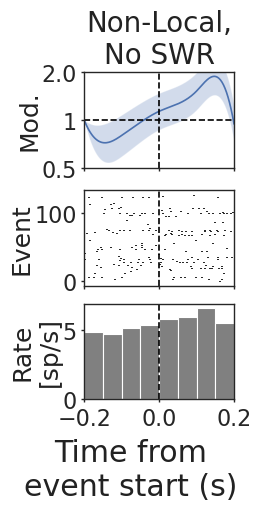

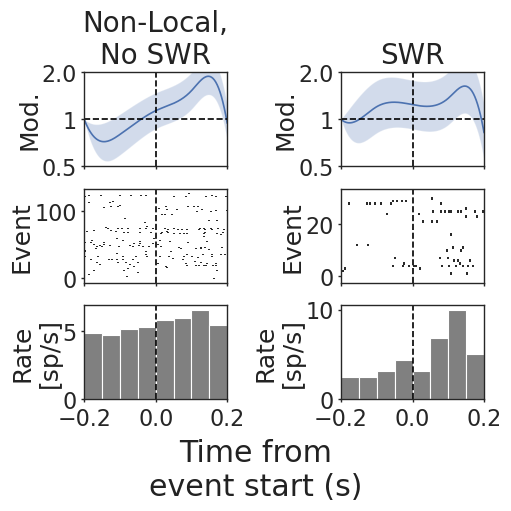

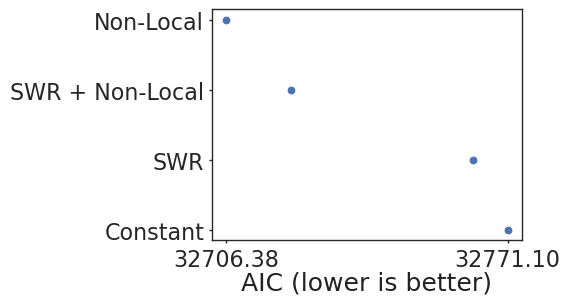

In [18]:
from src.pfc_analysis3 import _fit_immobility_models


# neuron_ind = 2
# neuron_ind = 16
# neuron_ind = 25
# neuron_ind = 27 # 27 is a good example
# neuron_ind = 52
# neuron_ind = 55
# neuron_ind = 61
# neuron_ind = 73
# neuron_ind = 81
# neuron_ind = 89
# neuron_ind = 90 # 90 is a good example
neuron_ind = 27
# neuron_ind = 90
neuron_spike_times = data["spike_times"]["mPFC"][neuron_ind]
neuron_spike_count = get_spikecount_per_time_bin(neuron_spike_times, time)

glm_results, glm_models = _fit_immobility_models(
    is_immobile, immobility_design_matrices, neuron_spike_count
)

model_list = ["non_local_no_SWR"]
plot_glm_results(
    lag_time,
    spline_basis,
    neuron_spike_times,
    glm_results,
    event_times,
    model_list=model_list,
)
model_list = ["non_local_no_SWR", "SWR"]
plot_glm_results(
    lag_time,
    spline_basis,
    neuron_spike_times,
    glm_results,
    event_times,
    model_list=model_list,
)

model_list = [
    "constant",
    "SWR",
    "SWR + non_local_no_SWR",
    "non_local",
]
plot_AICs(glm_results, model_list=model_list)

# Examples

In [11]:
import jax

device_id = 7
device = jax.devices()[device_id]
jax.config.update("jax_default_device", device)

device

StreamExecutorGpuDevice(id=7, process_index=0, slice_index=0)

In [12]:
from src.load_data_bandit import load_data
from non_local_detector import NonLocalClusterlessDetector
from non_local_detector.environment import Environment

from src.load_data_bandit import get_training_timepoints


data = load_data(nwb_file_name, epoch_name)

is_training = get_training_timepoints(data, training_type="no ripple")

env = Environment(
    place_bin_size=4.0,
)

position_std = 4.0
block_size = int(2**10)

clusterless_decoding_parameters = {
    "position_std": position_std,
    "waveform_std": 24.0,
    "block_size": block_size,
}
detector = NonLocalClusterlessDetector(
    environments=env,
    clusterless_algorithm_params=clusterless_decoding_parameters,
)


results = detector.estimate_parameters(
    position_time=data["position_info"].index.to_numpy(),
    position=data["position_info"][["head_position_x", "head_position_y"]].to_numpy(),
    spike_times=data["spike_times"]["HPC"],
    spike_waveform_features=data["spike_waveform_features"]["HPC"],
    time=data["position_info"].index.to_numpy(),
    is_training=is_training,
)

non_local_prob = results.acausal_state_probabilities.sel(
    states="Non-Local Continuous"
) + results.acausal_state_probabilities.sel(states="Non-Local Fragmented")

acausal_posterior = results.acausal_posterior.sel(state="Non-Local Continuous")
acausal_posterior += results.acausal_posterior.sel(state="Non-Local Fragmented")
acausal_posterior = acausal_posterior.unstack("state_bins")
acausal_posterior = acausal_posterior / acausal_posterior.sum(
    ["x_position", "y_position"]
)

[18:48:54][WARNING] Spyglass: Multiple classes found in stack: {'`lfp_merge`.`l_f_p_output`', '`lfp_v1`.`__l_f_p_v1`'}. Please submit a bug report with the snippet used.
26-May-24 18:48:54 Multiple classes found in stack: {'`lfp_merge`.`l_f_p_output`', '`lfp_v1`.`__l_f_p_v1`'}. Please submit a bug report with the snippet used.
26-May-24 18:49:06 Fitting initial conditions...
26-May-24 18:49:06 Fitting discrete state transition
26-May-24 18:49:06 Fitting continuous state transition...
26-May-24 18:49:07 Fitting clusterless spikes...


Encoding models:   0%|          | 0/13 [00:00<?, ?electrode/s]

26-May-24 18:49:20 Computing log likelihood...


Local Likelihood:   0%|          | 0/13 [00:00<?, ?electrode/s]

2024-05-26 18:49:38.066688: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:38.094121: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:44.420722: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:44.448641: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:50.131361: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:50.159060: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:54.812312: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:49:54.840193: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:50:02.547451: E external/o

No Spike Likelihood:   0%|          | 0/13 [00:00<?, ?cell/s]

Non-Local Likelihood:   0%|          | 0/13 [00:00<?, ?electrode/s]

2024-05-26 18:51:00.311202: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:01.780292: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:03.008997: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:03.867752: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:06.259987: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:08.066496: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:08.902564: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:10.243558: E external/org_tensorflow/tensorflow/compiler/xla/python/pjit.cc:461] fastpath_data is none
2024-05-26 18:51:11.759944: E external/o

In [13]:
import matplotlib.animation as animation
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from tqdm.auto import tqdm


def _setup_line(ax, color, xlim, ylim, ylabel, title=None):
    (line,) = ax.plot([], color=color, linewidth=2, animated=True, clip_on=False)
    ax.set_ylim(ylim)
    ax.set_xlim(xlim)
    ax.set_ylabel(ylabel)
    ax.set_facecolor("black")
    ax.spines["top"].set_color("black")
    ax.spines["right"].set_color("black")

    if title is not None:
        ax.set_title(title)

    return line


def _update_line(time_ind, line, window_time, df, window_factor):
    try:
        line.set_data(
            window_time,
            np.asarray(df.iloc[time_ind + window_factor]),
        )
    except IndexError:
        pass


def make_single_environment_movie(
    time_slice,
    position_info,
    posterior,
    non_local_prob,
    MUA_firing_rate,
    SWR_zscore,
    movie_name="video_name.mp4",
    sampling_frequency=500,
    video_slowdown=8,
    position_name=["head_position_x", "head_position_y"],
    direction_name="head_orientation",
    vmax=0.07,
):
    posterior = posterior.isel(time=time_slice)

    # Set up formatting for the movie files
    Writer = animation.writers["ffmpeg"]
    fps = sampling_frequency // video_slowdown
    writer = Writer(fps=fps, bitrate=-1)

    # Set up data
    map_position_ind = posterior.argmax(["x_position", "y_position"])
    map_position = np.stack(
        (
            posterior.x_position[map_position_ind["x_position"]],
            posterior.y_position[map_position_ind["y_position"]],
        ),
        axis=1,
    )

    position = np.asarray(position_info.iloc[time_slice][position_name])
    direction = np.asarray(position_info.iloc[time_slice][direction_name])

    window_size = 501

    window_ind = np.arange(window_size) - window_size // 2
    window_slice = slice(
        time_slice.start + window_ind[0], time_slice.stop + window_ind[-1]
    )
    non_local_prob = non_local_prob.iloc[window_slice]
    MUA_firing_rate = MUA_firing_rate.iloc[window_slice]
    SWR_zscore = SWR_zscore.iloc[window_slice]

    with plt.style.context("dark_background"):
        # Set up plots
        fig = plt.figure(layout="constrained", figsize=(6, 4))
        mosaic_list = [
            ["decode", "Non-Local"],
            ["decode", "SWR"],
            ["decode", "MUA"],
        ]

        ax_dict = fig.subplot_mosaic(mosaic_list, width_ratios=[2, 1])

        ax_dict["decode"].tick_params(colors="white", which="both")
        ax_dict["decode"].spines["bottom"].set_color("white")
        ax_dict["decode"].spines["left"].set_color("white")

        position_dot = ax_dict["decode"].scatter(
            [],
            [],
            s=80,
            zorder=102,
            color="magenta",
            label="actual position",
            animated=True,
        )
        (position_line,) = ax_dict["decode"].plot(
            [], [], color="magenta", linewidth=5, animated=True
        )
        map_dot = ax_dict["decode"].scatter(
            [],
            [],
            s=80,
            zorder=102,
            color="green",
            label="decoded position",
            animated=True,
        )
        (map_line,) = ax_dict["decode"].plot(
            [], [], "green", linewidth=3, animated=True
        )

        mesh = posterior.isel(time=0).plot(
            x="x_position",
            y="y_position",
            vmin=0.0,
            vmax=vmax,
            ax=ax_dict["decode"],
            animated=True,
            add_colorbar=False,
        )
        ax_dict["decode"].set_xlabel("")
        ax_dict["decode"].set_ylabel("")
        ax_dict["decode"].spines["top"].set_color("black")
        ax_dict["decode"].spines["right"].set_color("black")
        xlim = (
            position_info[position_name[0]].min() - 10,
            position_info[position_name[0]].max() + 10,
        )
        ylim = (
            position_info[position_name[1]].min() - 10,
            position_info[position_name[1]].max() + 10,
        )

        ax_dict["decode"].set_xlim(xlim)
        ax_dict["decode"].set_ylim(ylim)

        title = ax_dict["decode"].set_title(
            f"time = {posterior.isel(time=0).time.values:0.2f}",
        )
        fontprops = fm.FontProperties(size=16)
        scalebar = AnchoredSizeBar(
            ax_dict["decode"].transData,
            20,
            "20 cm",
            "lower right",
            pad=0.1,
            color="white",
            frameon=False,
            size_vertical=1,
            fontproperties=fontprops,
        )

        ax_dict["decode"].add_artist(scalebar)
        ax_dict["decode"].axis("off")

        # Non-Local
        line_xlim = (
            window_ind[0] / sampling_frequency,
            window_ind[-1] / sampling_frequency,
        )
        non_local_line = _setup_line(
            ax=ax_dict["Non-Local"],
            color=COLORS["Non-Local"],
            xlim=line_xlim,
            ylim=(0.0, 1.05),
            ylabel="Non-Local\nProb.",
            title="Non-Local",
        )

        # SWR
        ax_dict["SWR"].axhline(0, color="white", linestyle="--")
        swr_line = _setup_line(
            ax=ax_dict["SWR"],
            color=COLORS["SWR"],
            xlim=line_xlim,
            ylim=(-3.0, 10.0),
            ylabel="SWR [std]",
            title="SWR",
        )

        # MUA
        mua_line = _setup_line(
            ax=ax_dict["MUA"],
            color=COLORS["MUA"],
            xlim=line_xlim,
            ylim=(0.0, 3000.0),
            ylabel="MUA [sp/s]",
            title="MUA",
        )
        ax_dict["MUA"].set_xlabel("Time [s]")

        n_frames = posterior.shape[0]
        progress_bar = tqdm()
        progress_bar.reset(total=n_frames)
        window_time = window_ind / sampling_frequency
        window_factor = (window_size // 2) + window_ind

        def _update_plot(time_ind):
            start_ind = max(0, time_ind - 5)
            time_slice = slice(start_ind, time_ind)

            position_dot.set_offsets(position[time_ind])

            r = 4
            position_line.set_data(
                [
                    position[time_ind, 0],
                    position[time_ind, 0] + r * np.cos(direction[time_ind]),
                ],
                [
                    position[time_ind, 1],
                    position[time_ind, 1] + r * np.sin(direction[time_ind]),
                ],
            )

            map_dot.set_offsets(map_position[time_ind])
            map_line.set_data(map_position[time_slice, 0], map_position[time_slice, 1])

            mesh.set_array(posterior.isel(time=time_ind).values.ravel(order="F"))

            title.set_text(f"time = {posterior.isel(time=time_ind).time.values:0.2f}")

            _update_line(
                time_ind=time_ind,
                line=non_local_line,
                window_time=window_time,
                df=non_local_prob,
                window_factor=window_factor,
            )
            _update_line(
                time_ind=time_ind,
                line=swr_line,
                window_time=window_time,
                df=SWR_zscore,
                window_factor=window_factor,
            )
            _update_line(
                time_ind=time_ind,
                line=mua_line,
                window_time=window_time,
                df=MUA_firing_rate,
                window_factor=window_factor,
            )

            progress_bar.update()

            return (
                position_dot,
                position_line,
                map_dot,
                map_line,
                mesh,
                title,
                non_local_line,
                swr_line,
                mua_line,
            )

        movie = animation.FuncAnimation(
            fig, _update_plot, frames=n_frames, interval=1000 / fps, blit=True
        )
        if movie_name is not None:
            movie.save(movie_name, writer=writer, dpi=200)

        plt.close(fig)

In [ ]:
# event_times["non_local_no_SWR"], event_times["non_local_SWR"]

In [ ]:
event_type = "non_local_no_SWR"

for ind in range(len(event_times[event_type])):
    event = event_times[event_type].iloc[ind]

    time_slice = slice(
        np.searchsorted(time, event.start_time - 0.300),
        np.searchsorted(time, event.end_time + 0.300),
    )

    make_single_environment_movie(
        time_slice,
        data["position_info"],
        acausal_posterior,
        non_local_prob.to_dataframe().loc[:, ["acausal_state_probabilities"]],
        data["multiunit_firing_rate"]["HPC"],
        data["zscored_ripple_consensus_trace"].reindex(
            data["position_info"].index, method="nearest"
        ),
        movie_name=f"{nwb_file_name.replace('_.nwb', '')}_{epoch_name}_2D_{event_type}_{ind}.mp4",
        sampling_frequency=500,
        video_slowdown=8,
        position_name=["head_position_x", "head_position_y"],
        direction_name="head_orientation",
        vmax=0.07,
    )

In [ ]:
# ind = 23

event_type = "non_local_SWR"

for ind in range(len(event_times[event_type])):
    event = event_times[event_type].iloc[ind]

    time_slice = slice(
        np.searchsorted(time, event.start_time - 0.300),
        np.searchsorted(time, event.end_time + 0.300),
    )

    make_single_environment_movie(
        time_slice,
        data["position_info"],
        acausal_posterior,
        non_local_prob.to_dataframe().loc[:, ["acausal_state_probabilities"]],
        data["multiunit_firing_rate"]["HPC"],
        data["zscored_ripple_consensus_trace"].reindex(
            data["position_info"].index, method="nearest"
        ),
        movie_name=f"{nwb_file_name.replace('_.nwb', '')}_{epoch_name}_2D_{event_type}_{ind}.mp4",
        sampling_frequency=500,
        video_slowdown=8,
        position_name=["head_position_x", "head_position_y"],
        direction_name="head_orientation",
        vmax=0.07,
    )

In [39]:
# ind = 23

event_type = "SWR"
ind = 23

event = event_times[event_type].iloc[ind]

time_slice = slice(
    np.searchsorted(time, event.start_time - 0.300),
    np.searchsorted(time, event.end_time + 0.300),
)

make_single_environment_movie(
    time_slice,
    data["position_info"],
    acausal_posterior,
    non_local_prob.to_dataframe().loc[:, ["acausal_state_probabilities"]],
    data["multiunit_firing_rate"]["HPC"],
    data["zscored_ripple_consensus_trace"].reindex(
        data["position_info"].index, method="nearest"
    ),
    movie_name=f"{nwb_file_name.replace('_.nwb', '')}_{epoch_name}_2D_{event_type}_{ind}.mp4",
    sampling_frequency=500,
    video_slowdown=8,
    position_name=["head_position_x", "head_position_y"],
    direction_name="head_orientation",
    vmax=0.07,
)

0it [00:00, ?it/s]

26-May-24 21:29:59 Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
26-May-24 21:29:59 MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x800 -pix_fmt rgba -framerate 62 -loglevel error -i pipe: -vcodec h264 -pix_fmt yuv420p -y wilbur20210329_02_r1_2D_SWR_23.mp4


In [36]:
# SWR: 3, 10, 12/13, 15, 16, 22, 23
event_times["SWR"]

,start_time,end_time
id,,
0,1.617036e+09,1.617036e+09
1,1.617036e+09,1.617036e+09
2,1.617036e+09,1.617036e+09
3,1.617036e+09,1.617036e+09
4,1.617036e+09,1.617036e+09
...,...,...
122,1.617037e+09,1.617037e+09
123,1.617037e+09,1.617037e+09
124,1.617037e+09,1.617037e+09


In [ ]:
# non_local_no_SWR
## ind = 6, 10, 25, 29, 33, 45, 46, 47,

# what's up with 22, 23, 24?

In [48]:
event_type = "non_local_no_SWR"
ind = 47

event = event_times[event_type].iloc[ind]

time_slice = slice(
    np.searchsorted(time, event.start_time - 0.300),
    np.searchsorted(time, event.end_time + 0.300),
)

make_single_environment_movie(
    time_slice,
    data["position_info"],
    acausal_posterior,
    non_local_prob.to_dataframe().loc[:, ["acausal_state_probabilities"]],
    data["multiunit_firing_rate"]["HPC"],
    data["zscored_ripple_consensus_trace"].reindex(
        data["position_info"].index, method="nearest"
    ),
    movie_name=f"{nwb_file_name.replace('_.nwb', '')}_{epoch_name}_2D_{event_type}_{ind}.mp4",
    sampling_frequency=500,
    video_slowdown=8,
    position_name=["head_position_x", "head_position_y"],
    direction_name="head_orientation",
    vmax=0.07,
)

0it [00:00, ?it/s]

26-May-24 21:53:00 Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
26-May-24 21:53:00 MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x800 -pix_fmt rgba -framerate 62 -loglevel error -i pipe: -vcodec h264 -pix_fmt yuv420p -y wilbur20210329_02_r1_2D_non_local_no_SWR_47.mp4


In [45]:
len(event_times["non_local_no_SWR"])

296

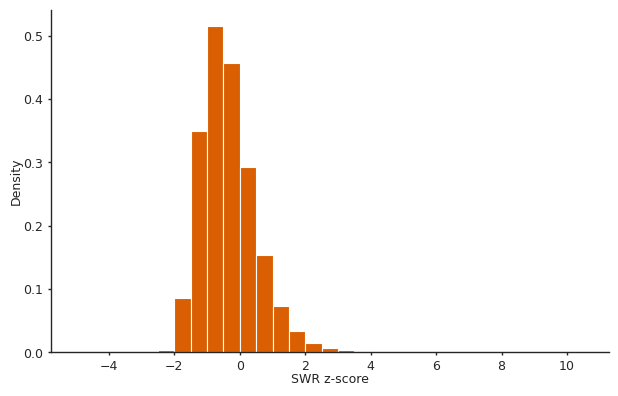

In [14]:
plt.hist(
    data["zscored_ripple_consensus_trace"]
    .reindex(data["position_info"].index, method="nearest")
    .loc[data["position_info"].head_speed < 4.0],
    bins=np.arange(-5, 11, 0.5),
    density=True,
    color=COLORS["SWR"],
)
plt.xlabel("SWR z-score")
plt.ylabel("Density")
sns.despine()

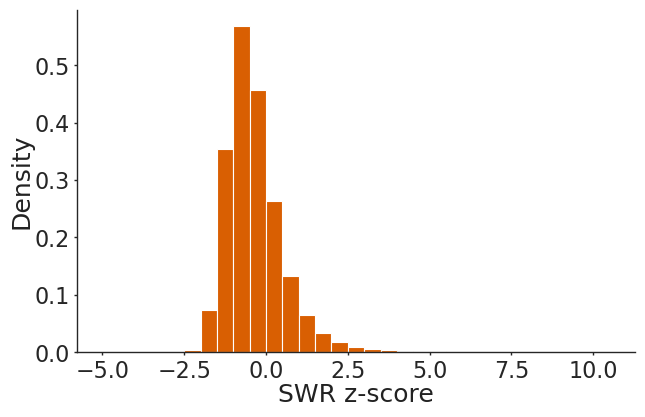

In [39]:
plt.hist(
    data_over_time["SWR_zscore"].loc[data_over_time["head_speed"] < 4.0],
    bins=np.arange(-5, 11, 0.5),
    density=True,
    color=COLORS["SWR"],
)
plt.xlabel("SWR z-score")
plt.ylabel("Density")
sns.despine()

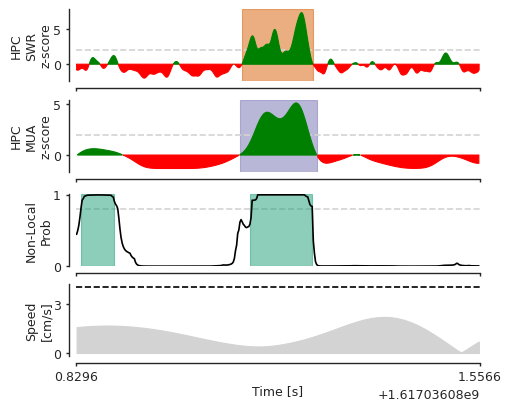

In [18]:
from src.plot_events import plot_event

ind = 4

t_slice = slice(
    event_times["SWR"].iloc[ind].start_time - 0.300,
    event_times["SWR"].iloc[ind].end_time + 0.300,
)
axis_names = [
    "SWR trace",
    "HPC MUA trace",
    "Non-local prob.",
    "speed",
]
plot_event(
    t_slice,
    data,
    event_times["non_local"],
    non_local_prob,
    acausal_posterior,
    axis_names=axis_names,
    figsize=(5, 4),
)

([], [])

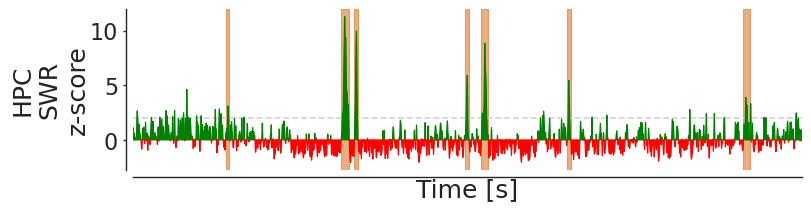

In [19]:
from src.plot_events import plot_event

ind = 40

t_slice = slice(
    event_times["SWR"].iloc[ind].start_time - 5.000,
    event_times["SWR"].iloc[ind].end_time + 5.000,
)
axis_names = [
    "SWR trace",
]
plot_event(
    t_slice,
    data,
    event_times["non_local"],
    non_local_prob,
    None,
    axis_names=axis_names,
    figsize=(8, 2.0),
)
plt.xticks([])

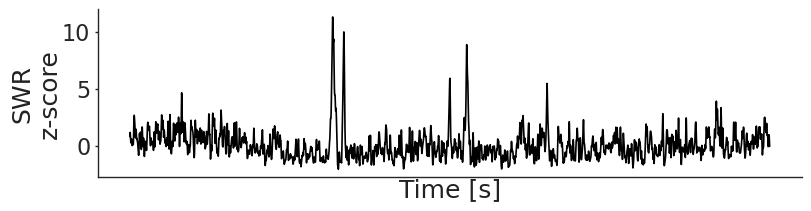

In [30]:
plt.figure(figsize=(8, 2.0), layout="constrained")
plt.plot(data["zscored_ripple_consensus_trace"].loc[t_slice], color="black")
plt.xlabel("Time [s]")
plt.ylabel("SWR\nz-score")
plt.xticks([])
sns.despine()

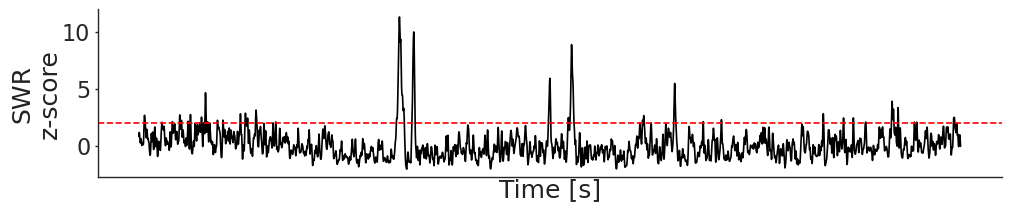

In [36]:
plt.figure(figsize=(10, 2.0), layout="constrained")
plt.plot(data["zscored_ripple_consensus_trace"].loc[t_slice], color="black")
plt.xlabel("Time [s]")
plt.ylabel("SWR\nz-score")
plt.xticks([])
plt.axhline(2.0, color="red", linestyle="--")
sns.despine()

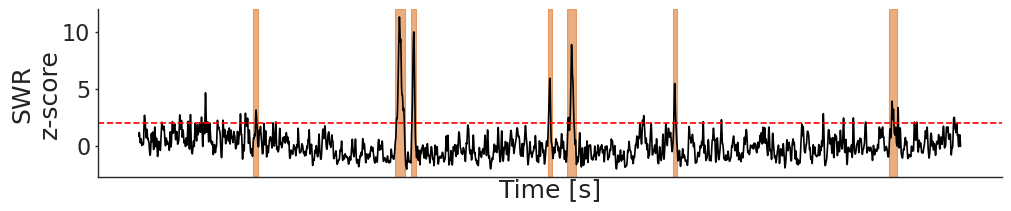

In [37]:
plt.figure(figsize=(10, 2.0), layout="constrained")
plt.plot(data["zscored_ripple_consensus_trace"].loc[t_slice], color="black")
plt.xlabel("Time [s]")
plt.ylabel("SWR\nz-score")
plt.xticks([])
plt.axhline(2.0, color="red", linestyle="--")
for _, rt in (
    data["ripple_times"]
    .loc[
        (data["ripple_times"].start_time > t_slice.start)
        & (data["ripple_times"].end_time < t_slice.stop)
    ]
    .iterrows()
):
    plt.axvspan(rt.start_time, rt.end_time, color=COLORS["SWR"], alpha=0.5)
sns.despine()

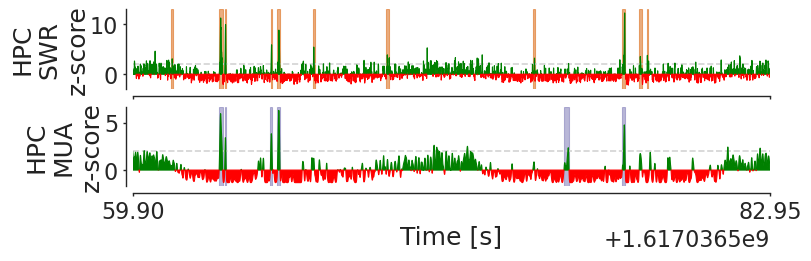

In [35]:
from src.plot_events import plot_event

ind = 40

t_slice = slice(
    event_times["SWR"].iloc[ind].start_time - 5.000,
    event_times["SWR"].iloc[ind].end_time + 18.000,
)
axis_names = [
    "SWR trace",
    "HPC MUA trace",
]
plot_event(
    t_slice,
    data,
    event_times["non_local"],
    non_local_prob,
    None,
    axis_names=axis_names,
    figsize=(8, 2.5),
)